# Fase 3 - Camada Gold: perguntas de negócio e gráficos

Pipeline Medallion (Raw → Silver → **Gold**) sobre os dados de **Viagens a Serviço**
do Portal da Transparência (6 meses de 2025).

Este notebook responde às 7 perguntas de negócio do projeto:

| Parte | Pergunta | Fonte |
|---|---|---|
| A | 4. Tipo de pagamento com maior valor médio | SQL direto na Silver |
| A | 5. Meio de transporte mais usado nos trechos | SQL direto na Silver |
| A | 6. UF de destino em mais trechos | SQL direto na Silver |
| B | 1. 5 órgãos com maior custo total | tabela/VIEW Gold |
| B | 2. 3 destinos com maior custo médio por viagem | tabela/VIEW Gold |
| B | 3. Viagem de maior duração e seu custo total | tabela/VIEW Gold |
| B | 7. Órgão que pagou mais no total | tabela/VIEW Gold |

**Regras de negócio (definidas na Fase 2):**

- `valor_total = valor_diarias + valor_passagens + valor_outros_gastos - valor_devolucao`
- `duracao_dias = data_fim - data_inicio + 1` (conta o dia inicial e o final)
- Pagamentos e passagens 100% idênticos foram tratados como duplicidade e mantidos uma única vez.

**Pré-requisito:** rodar `0_criar_banco.sql`, `1_extrair.py` e `2_transformar.py`, nessa ordem.

## 1. Preparação: bibliotecas, conexão e funções auxiliares

In [110]:
from decimal import Decimal

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from banco import conectar, executar

In [111]:
# Cores do projeto (paleta validada para daltonismo e contraste).
COR_PRINCIPAL = "#2a78d6"   # azul: série principal
COR_SECUNDARIA = "#eb6834"  # laranja: segunda série
COR_TEXTO = "#0b0b0b"
COR_TEXTO_SUAVE = "#52514e"
COR_GRADE = "#e3e2de"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": COR_TEXTO_SUAVE,
    "axes.labelcolor": COR_TEXTO_SUAVE,
    "xtick.color": COR_TEXTO_SUAVE,
    "ytick.color": COR_TEXTO_SUAVE,
    "axes.titlecolor": COR_TEXTO,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "font.size": 10,
})

# Guarda a resposta de cada pergunta para o resumo final.
respostas = {}

In [112]:
conexao = conectar()


def consultar(sql):
    """Executa um SELECT e devolve o resultado como DataFrame."""
    cursor = conexao.cursor()
    cursor.execute(sql)
    colunas = [coluna[0] for coluna in cursor.description]
    linhas = cursor.fetchall()
    cursor.close()
    tabela = pd.DataFrame(linhas, columns=colunas)
    for coluna in tabela.columns:
        if tabela[coluna].map(lambda v: isinstance(v, Decimal)).any():
            tabela[coluna] = tabela[coluna].astype(float)
    return tabela


def valor_unico(sql):
    """Executa um SELECT que devolve um único valor e retorna esse valor."""
    return consultar(sql).iloc[0, 0]


def moeda(valor):
    """Formata número como moeda brasileira: 1234.5 -> R$ 1.234,50."""
    texto = f"{valor:,.2f}".replace(",", "X").replace(".", ",")
    return "R$ " + texto.replace("X", ".")


def moeda_eixo(valor):
    """Formato curto para os eixos: 2500000 -> R$ 2,5 mi; 8000 -> R$ 8.000."""
    if abs(valor) >= 1_000_000:
        return "R$ " + f"{valor / 1_000_000:.1f}".replace(".", ",") + " mi"
    return "R$ " + inteiro(valor)


def inteiro(valor):
    """Formata inteiro com separador de milhar: 1234567 -> 1.234.567."""
    return f"{int(valor):,}".replace(",", ".")


def abreviar(texto, limite=38):
    """Encurta textos longos para caberem nos eixos dos gráficos."""
    texto = str(texto)
    return texto if len(texto) <= limite else texto[:limite - 3] + "..."


def mostrar(tabela, colunas_moeda=(), colunas_inteiro=()):
    """Exibe o DataFrame com valores formatados (sem alterar o original)."""
    copia = tabela.copy()
    for coluna in colunas_moeda:
        copia[coluna] = copia[coluna].map(moeda)
    for coluna in colunas_inteiro:
        copia[coluna] = copia[coluna].map(inteiro)
    display(copia.reset_index(drop=True))

In [113]:
def barras_horizontais(rotulos, valores, titulo, eixo_x, eixo_y, formatar,
                       formatar_eixo=None):
    """
    Gráfico de barras horizontais (maior valor no topo) com o valor
    escrito na ponta de cada barra. Uma única série, uma única cor.
    """
    fig, eixo = plt.subplots(figsize=(9, 0.55 * len(rotulos) + 1.6))
    posicoes = range(len(rotulos))
    barras = eixo.barh(posicoes, valores, height=0.55, color=COR_PRINCIPAL,
                        label=eixo_x)
    eixo.set_yticks(list(posicoes))
    eixo.set_yticklabels([abreviar(r) for r in rotulos])
    eixo.invert_yaxis()
    eixo.set_title(titulo)
    eixo.set_xlabel(eixo_x)
    eixo.set_ylabel(eixo_y)
    eixo.xaxis.grid(True, color=COR_GRADE, linewidth=0.8)
    eixo.set_axisbelow(True)
    eixo.legend(loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False)
    formatar_eixo = formatar_eixo or formatar
    eixo.xaxis.set_major_formatter(lambda v, _: formatar_eixo(v))
    limite = max(valores) * 1.22
    eixo.set_xlim(0, limite)
    for barra, valor in zip(barras, valores):
        meio_barra = barra.get_y() + barra.get_height() / 2
        eixo.text(valor + limite * 0.01, meio_barra, formatar(valor),
                  va="center", color=COR_TEXTO, fontsize=9)
    fig.tight_layout()
    plt.show()

In [114]:
# Teste rápido de conexão e do conteúdo da Silver.
contagens = consultar("""
    SELECT 'silver_viagem' AS tabela, COUNT(*) AS linhas FROM silver_viagem
    UNION ALL SELECT 'silver_pagamento', COUNT(*) FROM silver_pagamento
    UNION ALL SELECT 'silver_passagem', COUNT(*) FROM silver_passagem
    UNION ALL SELECT 'silver_trecho', COUNT(*) FROM silver_trecho
""")
mostrar(contagens, colunas_inteiro=["linhas"])

,tabela,linhas
0,silver_viagem,341.860
1,silver_pagamento,568.811
2,silver_passagem,167.210
3,silver_trecho,763.349


## 2. Parte A - Perguntas respondidas com SQL direto na Silver

Cada pergunta traz: **consulta SQL → tabela → gráfico → análise**.

### Pergunta 4 - Qual o tipo de pagamento com maior valor médio?

Consulta em `silver_pagamento`, agrupando por `tipo_pagamento`. A coluna `qtd_pagamentos`
mostra o tamanho de cada grupo, para não comparar médias de grupos muito pequenos sem perceber.

In [115]:
SQL_PERGUNTA_4 = """
    SELECT tipo_pagamento,
           COUNT(*)              AS qtd_pagamentos,
           ROUND(AVG(valor), 2)  AS valor_medio,
           ROUND(SUM(valor), 2)  AS valor_total
    FROM silver_pagamento
    WHERE valor IS NOT NULL
    GROUP BY tipo_pagamento
    ORDER BY valor_medio DESC
"""
p4 = consultar(SQL_PERGUNTA_4)
mostrar(p4, ["valor_medio", "valor_total"], ["qtd_pagamentos"])

,tipo_pagamento,qtd_pagamentos,valor_medio,valor_total
0,PASSAGEM,186.008,"R$ 1.856,78","R$ 345.375.576,94"
1,DIÁRIAS,366.351,"R$ 1.797,55","R$ 658.535.312,70"
2,Serviço correlato: seguro,4.882,"R$ 447,72","R$ 2.185.792,32"
3,RESTITUIÇÃO,11.570,"R$ 245,69","R$ 2.842.678,82"


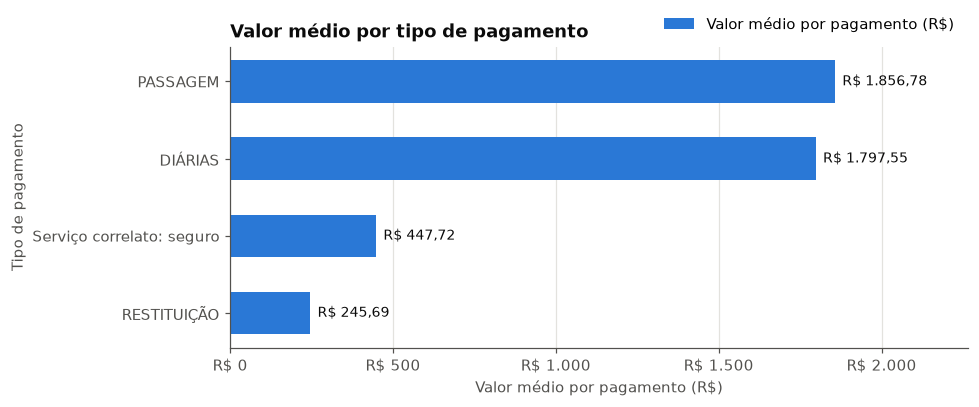

Análise: O tipo 'PASSAGEM' tem o maior valor médio: R$ 1.856,78 por pagamento (1.0x a média geral de R$ 1.773,77), em 186.008 pagamentos.


In [116]:
barras_horizontais(
    p4["tipo_pagamento"], p4["valor_medio"],
    titulo="Valor médio por tipo de pagamento",
    eixo_x="Valor médio por pagamento (R$)",
    eixo_y="Tipo de pagamento",
    formatar=moeda,
    formatar_eixo=moeda_eixo,
)

lider = p4.iloc[0]
media_geral = (p4["valor_total"].sum() / p4["qtd_pagamentos"].sum())
insight = (
    f"O tipo '{lider['tipo_pagamento']}' tem o maior valor médio: "
    f"{moeda(lider['valor_medio'])} por pagamento "
    f"({lider['valor_medio'] / media_geral:.1f}x a média geral de "
    f"{moeda(media_geral)}), em {inteiro(lider['qtd_pagamentos'])} pagamentos."
)
respostas["Pergunta 4"] = insight
print("Análise:", insight)

### Pergunta 5 - Qual o meio de transporte mais usado nos trechos?

Consulta em `silver_trecho`, contando os trechos por `meio_transporte`.
Trechos sem o meio informado entram como "Não informado".

In [117]:
SQL_PERGUNTA_5 = """
    SELECT COALESCE(meio_transporte, 'Não informado') AS meio_transporte,
           COUNT(*) AS qtd_trechos,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS percentual
    FROM silver_trecho
    GROUP BY COALESCE(meio_transporte, 'Não informado')
    ORDER BY qtd_trechos DESC
"""
p5 = consultar(SQL_PERGUNTA_5)
mostrar(p5, colunas_inteiro=["qtd_trechos"])

,meio_transporte,qtd_trechos,percentual
0,Veículo Oficial,386.424,50.62
1,Aéreo,232.666,30.48
2,Rodoviário,64.970,8.51
3,Veículo Próprio,42.846,5.61
4,Inválido,26.659,3.49
5,Fluvial,8.429,1.10
6,Ferroviário,874,0.11
7,Marítimo,481,0.06


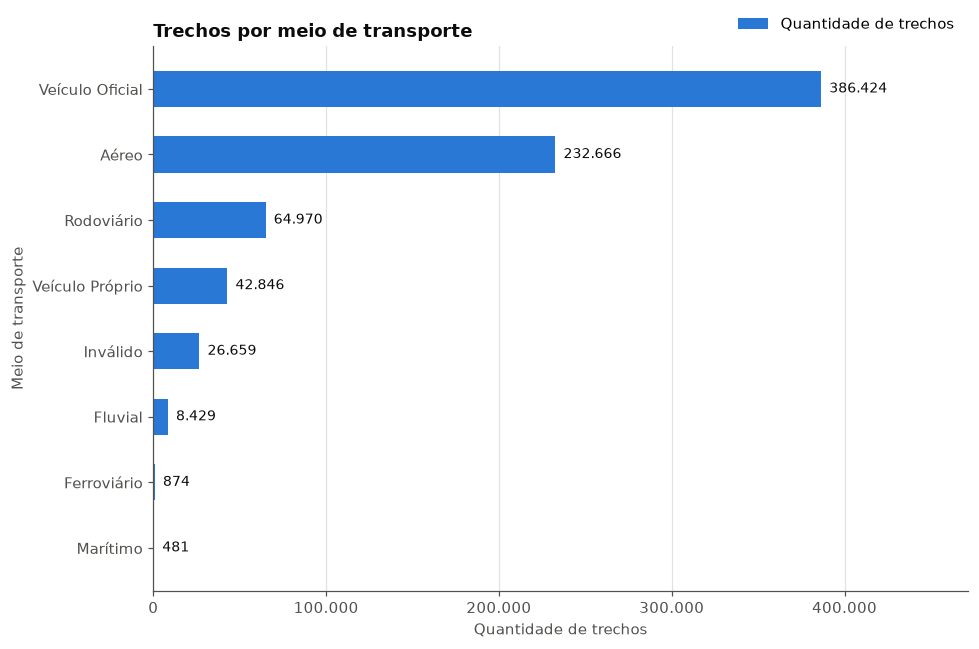

Análise: 'Veículo Oficial' é o meio mais usado: 386.424 trechos, 50.6% do total. O segundo colocado é 'Aéreo', com 30.5%.


In [118]:
barras_horizontais(
    p5["meio_transporte"], p5["qtd_trechos"],
    titulo="Trechos por meio de transporte",
    eixo_x="Quantidade de trechos",
    eixo_y="Meio de transporte",
    formatar=inteiro,
)

lider = p5.iloc[0]
insight = (
    f"'{lider['meio_transporte']}' é o meio mais usado: "
    f"{inteiro(lider['qtd_trechos'])} trechos, "
    f"{lider['percentual']:.1f}% do total."
)
if len(p5) > 1:
    segundo = p5.iloc[1]
    insight += (
        f" O segundo colocado é '{segundo['meio_transporte']}', com "
        f"{segundo['percentual']:.1f}%."
    )
respostas["Pergunta 5"] = insight
print("Análise:", insight)

### Pergunta 6 - Qual UF de destino aparece em mais trechos?

Consulta em `silver_trecho`, contando os trechos por `destino_uf`.

Como a volta para a cidade de origem também é um trecho, a UF-base dos viajantes tende a
liderar a contagem. Por isso o gráfico compara **todos os trechos** com **apenas o 1º trecho
de cada viagem** (a ida), que mostra para onde as pessoas realmente vão.

In [119]:
SQL_PERGUNTA_6_TODOS = """
    SELECT destino_uf AS uf, COUNT(*) AS qtd_trechos
    FROM silver_trecho
    WHERE destino_uf IS NOT NULL
    GROUP BY destino_uf
    ORDER BY qtd_trechos DESC
"""
SQL_PERGUNTA_6_IDA = """
    SELECT destino_uf AS uf, COUNT(*) AS qtd_trechos_ida
    FROM silver_trecho
    WHERE destino_uf IS NOT NULL AND sequencia_trecho = 1
    GROUP BY destino_uf
"""
todos = consultar(SQL_PERGUNTA_6_TODOS)
ida = consultar(SQL_PERGUNTA_6_IDA)
p6 = todos.head(10).merge(ida, on="uf", how="left").fillna(0)
p6["qtd_trechos_ida"] = p6["qtd_trechos_ida"].astype(int)
mostrar(p6, colunas_inteiro=["qtd_trechos", "qtd_trechos_ida"])

,uf,qtd_trechos,qtd_trechos_ida
0,São Paulo,82.722,36.741
1,Distrito Federal,79.962,25.382
2,Minas Gerais,50.965,20.408
3,Rio de Janeiro,44.197,16.797
4,Paraná,42.603,16.134
5,Pará,40.044,13.734
6,Rio Grande do Sul,38.684,15.201
7,Mato Grosso do Sul,30.516,10.486
8,Bahia,28.375,11.074
9,Pernambuco,28.372,10.126


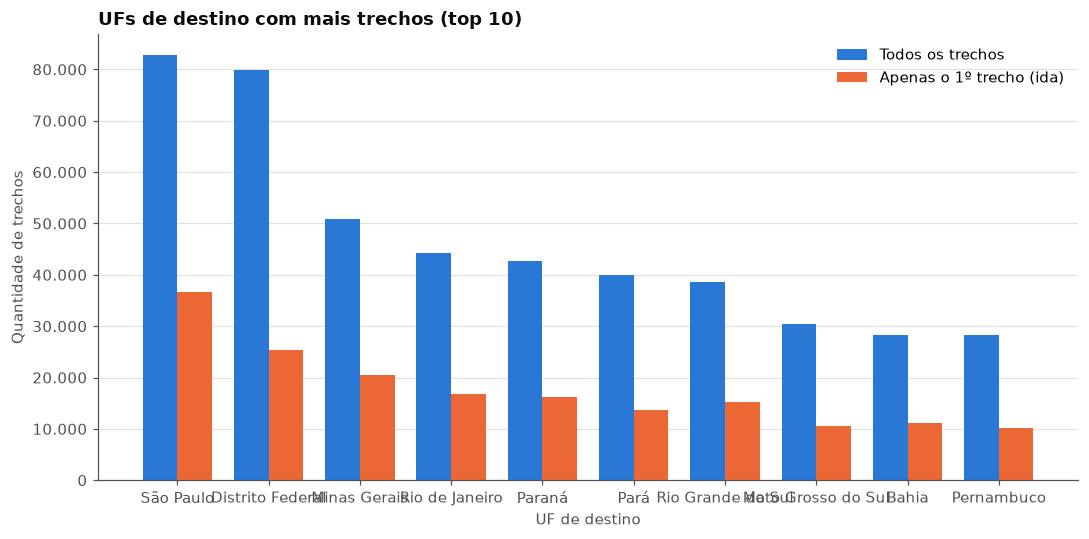

Análise: A UF de destino em mais trechos é São Paulo, com 82.722 trechos (11.1% do total). Considerando só a ida (1º trecho), São Paulo continua líder, com 36.741 trechos.


In [120]:
fig, eixo = plt.subplots(figsize=(10, 5))
largura = 0.38
x = range(len(p6))
eixo.bar([i - largura / 2 for i in x], p6["qtd_trechos"], width=largura,
         color=COR_PRINCIPAL, label="Todos os trechos")
eixo.bar([i + largura / 2 for i in x], p6["qtd_trechos_ida"], width=largura,
         color=COR_SECUNDARIA, label="Apenas o 1º trecho (ida)")
eixo.set_xticks(list(x))
eixo.set_xticklabels(p6["uf"])
eixo.set_title("UFs de destino com mais trechos (top 10)")
eixo.set_xlabel("UF de destino")
eixo.set_ylabel("Quantidade de trechos")
eixo.yaxis.set_major_formatter(lambda v, _: inteiro(v))
eixo.yaxis.grid(True, color=COR_GRADE, linewidth=0.8)
eixo.set_axisbelow(True)
eixo.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

lider = p6.iloc[0]
pct = 100 * lider["qtd_trechos"] / todos["qtd_trechos"].sum()
insight = (
    f"A UF de destino em mais trechos é {lider['uf']}, com "
    f"{inteiro(lider['qtd_trechos'])} trechos ({pct:.1f}% do total)."
)
lider_ida = ida.sort_values("qtd_trechos_ida", ascending=False).iloc[0]
if lider_ida["uf"] != lider["uf"]:
    insight += (
        f" Considerando só a ida (1º trecho), a UF líder muda para "
        f"{lider_ida['uf']} ({inteiro(lider_ida['qtd_trechos_ida'])} trechos)."
    )
else:
    insight += (
        f" Considerando só a ida (1º trecho), {lider_ida['uf']} continua "
        f"líder, com {inteiro(lider_ida['qtd_trechos_ida'])} trechos."
    )
respostas["Pergunta 6"] = insight
print("Análise:", insight)

## 3. Camada Gold - tabelas e VIEWs agregadas (JOIN + GROUP BY)

A Gold reúne os dados da Silver já agregados para responder às perguntas de negócio.
Cada agregação é criada **duas vezes** no banco, com o mesmo `SELECT`:

- como **tabela** `gold_*` (dados gravados, rápida para consultar);
- como **VIEW** `gold_vw_*` (sempre reflete a Silver atual).

Para não multiplicar linhas ao juntar tabelas de 1 para muitos (uma viagem tem vários
pagamentos e vários trechos), as tabelas filhas são **agregadas antes do JOIN**.

O campo `destinos` traz todas as cidades da viagem em um só texto, separadas por ", " e
frequentemente repetidas (ex.: "Brasília/DF, Brasília/DF, Rio de Janeiro/RJ"). Em `gold_destino_custo`
o texto é **separado em destinos individuais** (até 100 por viagem) e repetições dentro da mesma viagem
são contadas uma vez. Uma viagem com vários destinos entra no cálculo de cada um deles.

| Objeto Gold | O que agrega | Responde |
|---|---|---|
| `gold_orgao_custo` | viagens por órgão superior (JOIN com trechos) | Pergunta 1 |
| `gold_destino_custo` | viagens por destino individual (JOIN com viagem e trechos) | Pergunta 2 |
| `gold_viagem_resumo` | uma linha por viagem (JOIN com pagamentos) | Pergunta 3 |
| `gold_pagamento_orgao` | pagamentos por órgão pagador (JOIN com viagem) | Pergunta 7 |

In [121]:
SQL_GOLD = {
    "orgao_custo": """
        SELECT v.nome_orgao_superior                 AS orgao,
               COUNT(*)                              AS qtd_viagens,
               SUM(v.valor_total)                    AS custo_total,
               ROUND(AVG(v.valor_total), 2)          AS custo_medio,
               ROUND(AVG(v.duracao_dias), 1)         AS duracao_media_dias,
               SUM(COALESCE(t.qtd_trechos, 0))       AS qtd_trechos
        FROM silver_viagem v
        LEFT JOIN (
            SELECT id_viagem, COUNT(*) AS qtd_trechos
            FROM silver_trecho
            GROUP BY id_viagem
        ) t ON t.id_viagem = v.id_viagem
        GROUP BY v.nome_orgao_superior
    """,
    "destino_custo": """
        SELECT vd.destino                            AS destino,
               COUNT(*)                              AS qtd_viagens,
               SUM(v.valor_total)                    AS custo_total,
               ROUND(AVG(v.valor_total), 2)          AS custo_medio,
               ROUND(AVG(v.duracao_dias), 1)         AS duracao_media_dias,
               SUM(COALESCE(t.qtd_trechos, 0))       AS qtd_trechos
        FROM (
            SELECT DISTINCT v2.id_viagem,
                   TRIM(SUBSTRING_INDEX(
                       SUBSTRING_INDEX(v2.destinos, ', ', numeros.n),
                       ', ', -1))                    AS destino
            FROM silver_viagem v2
            JOIN (
                SELECT a.d + 10 * b.d + 1 AS n
                FROM (SELECT 0 AS d UNION ALL SELECT 1 UNION ALL SELECT 2
                      UNION ALL SELECT 3 UNION ALL SELECT 4 UNION ALL SELECT 5
                      UNION ALL SELECT 6 UNION ALL SELECT 7 UNION ALL SELECT 8
                      UNION ALL SELECT 9) a
                CROSS JOIN (SELECT 0 AS d UNION ALL SELECT 1 UNION ALL SELECT 2
                      UNION ALL SELECT 3 UNION ALL SELECT 4 UNION ALL SELECT 5
                      UNION ALL SELECT 6 UNION ALL SELECT 7 UNION ALL SELECT 8
                      UNION ALL SELECT 9) b
            ) numeros
              ON numeros.n <= 1 + (
                     LENGTH(v2.destinos)
                     - LENGTH(REPLACE(v2.destinos, ', ', ''))) / 2
            WHERE v2.destinos IS NOT NULL AND v2.destinos <> ''
        ) vd
        JOIN silver_viagem v ON v.id_viagem = vd.id_viagem
        LEFT JOIN (
            SELECT id_viagem, COUNT(*) AS qtd_trechos
            FROM silver_trecho
            GROUP BY id_viagem
        ) t ON t.id_viagem = v.id_viagem
        WHERE vd.destino <> ''
        GROUP BY vd.destino
    """,
    "viagem_resumo": """
        SELECT v.id_viagem,
               v.nome_orgao_superior                 AS orgao,
               v.destinos                            AS destino,
               v.data_inicio,
               v.data_fim,
               v.duracao_dias,
               v.valor_total,
               COUNT(p.id_pagamento)                 AS qtd_pagamentos,
               COALESCE(SUM(p.valor), 0)             AS total_pago
        FROM silver_viagem v
        LEFT JOIN silver_pagamento p ON p.id_viagem = v.id_viagem
        GROUP BY v.id_viagem, v.nome_orgao_superior, v.destinos,
                 v.data_inicio, v.data_fim, v.duracao_dias, v.valor_total
    """,
    "pagamento_orgao": """
        SELECT COALESCE(p.nome_orgao_pagador, 'Não informado')
                                                     AS orgao_pagador,
               COUNT(*)                              AS qtd_pagamentos,
               COUNT(DISTINCT p.id_viagem)           AS qtd_viagens,
               SUM(p.valor)                          AS total_pago,
               ROUND(AVG(p.valor), 2)                AS valor_medio
        FROM silver_pagamento p
        JOIN silver_viagem v ON v.id_viagem = p.id_viagem
        GROUP BY COALESCE(p.nome_orgao_pagador, 'Não informado')
    """,
}

In [122]:
def criar_objetos_gold():
    """Recria cada agregação como tabela (gold_*) e como VIEW (gold_vw_*)."""
    for nome, sql_select in SQL_GOLD.items():
        executar(conexao, f"DROP VIEW IF EXISTS gold_vw_{nome}")
        executar(conexao, f"DROP TABLE IF EXISTS gold_{nome}")
        executar(conexao, f"CREATE TABLE gold_{nome} AS {sql_select}")
        executar(conexao, f"CREATE VIEW gold_vw_{nome} AS {sql_select}")


criar_objetos_gold()

objetos = consultar("""
    SELECT table_name AS objeto, table_type AS tipo
    FROM information_schema.tables
    WHERE table_schema = DATABASE() AND table_name LIKE 'gold\\_%'
    ORDER BY table_name
""")
mostrar(objetos)

,objeto,tipo
0,gold_destino_custo,BASE TABLE
1,gold_orgao_custo,BASE TABLE
2,gold_pagamento_orgao,BASE TABLE
3,gold_viagem_resumo,BASE TABLE
4,gold_vw_destino_custo,VIEW
5,gold_vw_orgao_custo,VIEW
6,gold_vw_pagamento_orgao,VIEW
7,gold_vw_viagem_resumo,VIEW


### Validação da Gold

Duas conferências para garantir que o JOIN não multiplicou valores:

1. a tabela e a VIEW de cada agregação têm o mesmo número de linhas;
2. os totais da Gold batem com os totais da Silver.

In [123]:
def validar_gold():
    """Compara tabela x VIEW e os totais da Gold com os da Silver."""
    resultado = []
    for nome in SQL_GOLD:
        n_tabela = valor_unico(f"SELECT COUNT(*) FROM gold_{nome}")
        n_view = valor_unico(f"SELECT COUNT(*) FROM gold_vw_{nome}")
        resultado.append((f"linhas: gold_{nome} x gold_vw_{nome}",
                          inteiro(n_tabela), inteiro(n_view),
                          n_tabela == n_view))

    comparacoes = [
        ("custo total: silver_viagem x gold_orgao_custo",
         "SELECT SUM(valor_total) AS v FROM silver_viagem",
         "SELECT SUM(custo_total) AS v FROM gold_orgao_custo"),
        ("total pago: silver_pagamento x gold_pagamento_orgao",
         "SELECT SUM(valor) AS v FROM silver_pagamento",
         "SELECT SUM(total_pago) AS v FROM gold_pagamento_orgao"),
        ("total pago: silver_pagamento x gold_viagem_resumo",
         "SELECT SUM(valor) AS v FROM silver_pagamento",
         "SELECT SUM(total_pago) AS v FROM gold_viagem_resumo"),
    ]
    for nome, sql_silver, sql_gold in comparacoes:
        valor_silver = valor_unico(sql_silver)
        valor_gold = valor_unico(sql_gold)
        resultado.append((nome, moeda(valor_silver), moeda(valor_gold),
                          abs(valor_silver - valor_gold) < 0.01))

    viagens_silver = valor_unico("SELECT COUNT(*) AS v FROM silver_viagem")
    viagens_gold = valor_unico("SELECT COUNT(*) AS v FROM gold_viagem_resumo")
    resultado.append(("viagens: silver_viagem x gold_viagem_resumo",
                      inteiro(viagens_silver), inteiro(viagens_gold),
                      viagens_silver == viagens_gold))

    colunas = ["conferência", "origem", "gold", "ok"]
    tabela = pd.DataFrame(resultado, columns=colunas)
    tabela["ok"] = tabela["ok"].map({True: "OK", False: "DIVERGENTE"})
    mostrar(tabela)
    return all(item[3] for item in resultado)


assert validar_gold(), "A Gold diverge da Silver: revise os JOINs."

,conferência,origem,gold,ok
0,linhas: gold_orgao_custo x gold_vw_orgao_custo,35,35,OK
1,linhas: gold_destino_custo x gold_vw_destino_c...,5.757,5.757,OK
2,linhas: gold_viagem_resumo x gold_vw_viagem_re...,341.860,341.860,OK
3,linhas: gold_pagamento_orgao x gold_vw_pagamen...,216,216,OK
4,custo total: silver_viagem x gold_orgao_custo,"R$ 1.188.144.731,13","R$ 1.188.144.731,13",OK
5,total pago: silver_pagamento x gold_pagamento_...,"R$ 1.008.939.360,78","R$ 1.008.939.360,78",OK
6,total pago: silver_pagamento x gold_viagem_resumo,"R$ 1.008.939.360,78","R$ 1.008.939.360,78",OK
7,viagens: silver_viagem x gold_viagem_resumo,341.860,341.860,OK


## 4. Parte B - Perguntas respondidas a partir da Gold

Aqui as consultas leem as tabelas `gold_*` criadas acima (as VIEWs `gold_vw_*` retornam o mesmo resultado).

### Pergunta 1 - Quais os 5 órgãos com maior custo total?

Fonte: `gold_orgao_custo`. O custo total de cada órgão é a soma de `valor_total` das suas viagens.

In [124]:
SQL_PERGUNTA_1 = """
    SELECT orgao, qtd_viagens, custo_total, custo_medio
    FROM gold_orgao_custo
    ORDER BY custo_total DESC
    LIMIT 5
"""
p1 = consultar(SQL_PERGUNTA_1)
mostrar(p1, ["custo_total", "custo_medio"], ["qtd_viagens"])

,orgao,qtd_viagens,custo_total,custo_medio
0,Ministério da Justiça e Segurança Pública,75.742,"R$ 486.933.121,65","R$ 6.428,84"
1,Ministério da Defesa,61.912,"R$ 156.070.304,49","R$ 2.520,84"
2,Ministério da Educação,65.295,"R$ 111.291.349,34","R$ 1.704,44"
3,Ministério do Meio Ambiente e Mudança do Clima,19.413,"R$ 49.697.710,16","R$ 2.560,02"
4,Ministério da Previdência Social,8.190,"R$ 40.417.309,06","R$ 4.934,96"


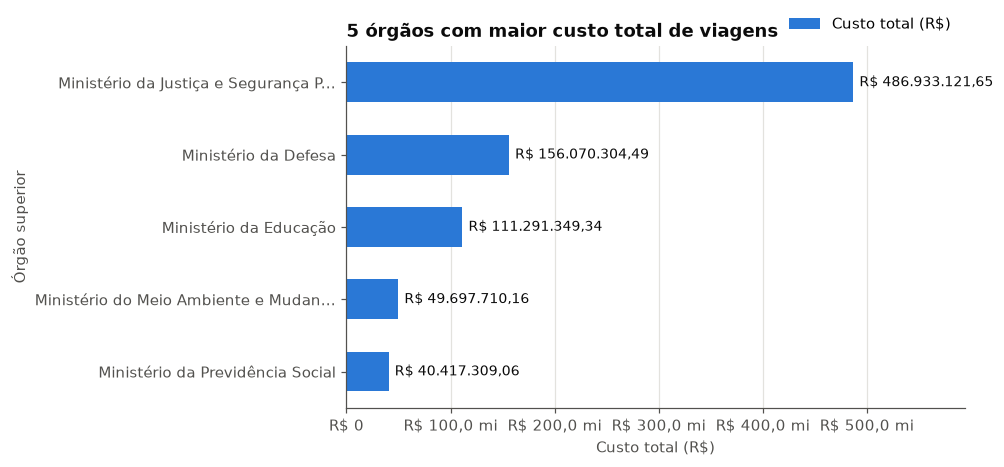

Análise: 'Ministério da Justiça e Segurança Pública' é o órgão de maior custo: R$ 486.933.121,65 (41.0% de todo o custo). Os 5 maiores somam 71.1% do total, o que mostra o grau de concentração dos gastos.


In [125]:
barras_horizontais(
    p1["orgao"], p1["custo_total"],
    titulo="5 órgãos com maior custo total de viagens",
    eixo_x="Custo total (R$)",
    eixo_y="Órgão superior",
    formatar=moeda,
    formatar_eixo=moeda_eixo,
)

custo_geral = valor_unico("SELECT SUM(custo_total) AS v FROM gold_orgao_custo")
lider = p1.iloc[0]
insight = (
    f"'{lider['orgao']}' é o órgão de maior custo: "
    f"{moeda(lider['custo_total'])} "
    f"({100 * lider['custo_total'] / custo_geral:.1f}% de todo o custo). "
    f"Os 5 maiores somam {100 * p1['custo_total'].sum() / custo_geral:.1f}% "
    f"do total, o que mostra o grau de concentração dos gastos."
)
respostas["Pergunta 1"] = insight
print("Análise:", insight)

### Pergunta 2 - Quais os 3 destinos com maior custo médio por viagem?

Fonte: `gold_destino_custo` (um destino por linha, já separado do campo `destinos`).
O custo médio de um destino é a média de `valor_total` das viagens que passaram por ele.

Duas regras para o ranking fazer sentido:

- um destino com poucas viagens pode ter média alta por causa de um caso isolado; por isso só entram destinos com
  **pelo menos `MIN_VIAGENS` viagens**;
- "Informações protegidas por sigilo" não é um lugar, então fica fora do ranking.

A tabela sem o filtro de quantidade mínima também é exibida, para ficar claro o efeito da regra.

In [126]:
MIN_VIAGENS = 30
FILTRO_SIGILO = "destino NOT LIKE '%sigilo%'"

SQL_PERGUNTA_2 = f"""
    SELECT destino, qtd_viagens, custo_medio, custo_total
    FROM gold_destino_custo
    WHERE qtd_viagens >= {MIN_VIAGENS} AND {FILTRO_SIGILO}
    ORDER BY custo_medio DESC
    LIMIT 3
"""
p2 = consultar(SQL_PERGUNTA_2)
assert not p2.empty, "Nenhum destino atingiu MIN_VIAGENS: reduza o valor."
print(f"Ranking oficial (destinos com pelo menos {MIN_VIAGENS} viagens):")
mostrar(p2, ["custo_medio", "custo_total"], ["qtd_viagens"])

sem_filtro = consultar(f"""
    SELECT destino, qtd_viagens, custo_medio
    FROM gold_destino_custo
    WHERE {FILTRO_SIGILO}
    ORDER BY custo_medio DESC
    LIMIT 3
""")
print("Para comparação, sem o filtro de quantidade mínima:")
mostrar(sem_filtro, ["custo_medio"], ["qtd_viagens"])

Ranking oficial (destinos com pelo menos 30 viagens):


,destino,qtd_viagens,custo_medio,custo_total
0,Sananduva/RS,93,"R$ 87.164,61","R$ 8.106.309,19"
1,Monte Negro/RO,96,"R$ 86.612,71","R$ 8.314.820,52"
2,Nonoai/RS,116,"R$ 78.584,97","R$ 9.115.856,76"


Para comparação, sem o filtro de quantidade mínima:


,destino,qtd_viagens,custo_medio
0,Brasí,1,"R$ 123.460,00"
1,Plácido de Cas,1,"R$ 115.775,00"
2,"Apuí/AM,",1,"R$ 114.532,50"


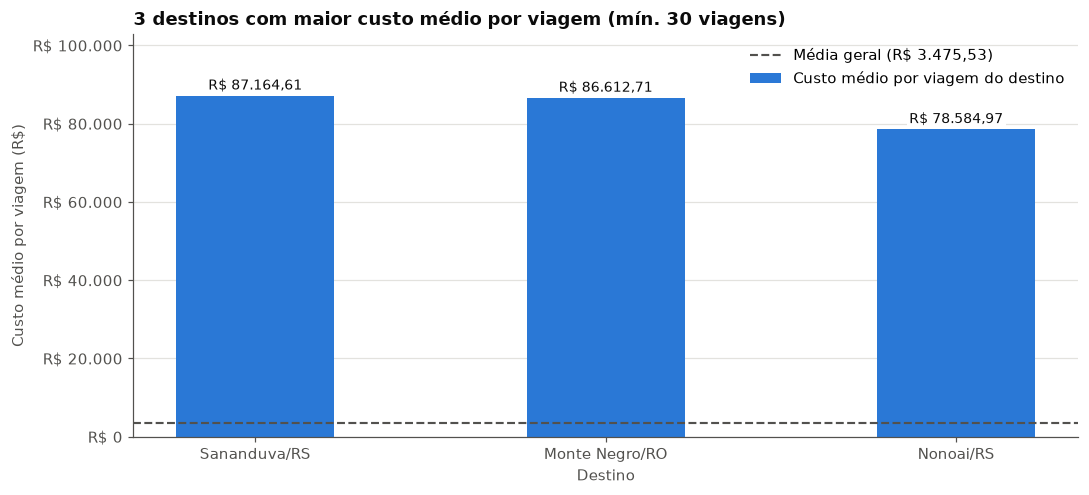

Análise: 'Sananduva/RS' tem o maior custo médio: R$ 87.164,61 por viagem, 25.1x a média geral (R$ 3.475,53), em 93 viagens.


In [127]:
custo_medio_geral = valor_unico(
    "SELECT AVG(valor_total) AS v FROM silver_viagem"
)

fig, eixo = plt.subplots(figsize=(10, 4.6))
posicoes = list(range(len(p2)))
barras = eixo.bar(posicoes, p2["custo_medio"], width=0.45,
                  color=COR_PRINCIPAL,
                  label="Custo médio por viagem do destino")
eixo.set_xticks(posicoes)
eixo.set_xticklabels([abreviar(d, 30) for d in p2["destino"]])
eixo.axhline(custo_medio_geral, color=COR_TEXTO_SUAVE, linestyle="--",
             linewidth=1.4, label=f"Média geral ({moeda(custo_medio_geral)})")
eixo.set_title("3 destinos com maior custo médio por viagem "
               f"(mín. {MIN_VIAGENS} viagens)")
eixo.set_xlabel("Destino")
eixo.set_ylabel("Custo médio por viagem (R$)")
eixo.yaxis.set_major_formatter(lambda v, _: moeda_eixo(v))
eixo.yaxis.grid(True, color=COR_GRADE, linewidth=0.8)
eixo.set_axisbelow(True)
topo = max(p2["custo_medio"].max(), custo_medio_geral) * 1.18
eixo.set_ylim(0, topo)
for barra, valor in zip(barras, p2["custo_medio"]):
    eixo.text(barra.get_x() + barra.get_width() / 2, valor + topo * 0.015,
              moeda(valor), ha="center", color=COR_TEXTO, fontsize=9,
              zorder=5, bbox={"facecolor": "white", "edgecolor": "none",
                              "pad": 1.5})
eixo.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

lider = p2.iloc[0]
insight = (
    f"'{lider['destino']}' tem o maior custo médio: "
    f"{moeda(lider['custo_medio'])} por viagem, "
    f"{lider['custo_medio'] / custo_medio_geral:.1f}x a média geral "
    f"({moeda(custo_medio_geral)}), em "
    f"{inteiro(lider['qtd_viagens'])} viagens."
)
respostas["Pergunta 2"] = insight
print("Análise:", insight)

### Pergunta 3 - Qual a viagem de maior duração e seu custo total?

Fonte: `gold_viagem_resumo` (uma linha por viagem, com o valor pago somado dos pagamentos).
Em caso de empate na duração, vale a viagem de maior custo.

A viagem mais longa pode ter custo zero (por exemplo, viagem sem despesas registradas) ou até negativo (devolução maior que os gastos). Por isso a análise
também mostra a viagem mais longa **entre as que tiveram custo maior que zero**.

In [128]:
SQL_PERGUNTA_3 = """
    SELECT id_viagem, orgao, destino, data_inicio, data_fim,
           duracao_dias, valor_total, total_pago
    FROM gold_viagem_resumo
    WHERE duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC, valor_total DESC
    LIMIT 5
"""
p3 = consultar(SQL_PERGUNTA_3)
p3["destino"] = p3["destino"].map(lambda d: abreviar(d, 45))
mostrar(p3, ["valor_total", "total_pago"], ["duracao_dias"])

,id_viagem,orgao,destino,data_inicio,data_fim,duracao_dias,valor_total,total_pago
0,0000000000020699856,Ministério da Previdência Social,Mogi Mirim/SP,2025-01-13,2026-01-31,384,"R$ 0,00","R$ 0,00"
1,0000000000020793594,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-02,2026-01-15,379,"R$ 120.650,00","R$ 35.150,00"
2,0000000000020793492,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-11,2026-01-15,370,"R$ 113.382,50","R$ 41.657,50"
3,0000000000020774569,Ministério da Educação,Bariloche/Argentina,2025-02-26,2026-03-02,370,"R$ 0,00","R$ 0,00"
4,0000000000020592696,Ministério da Justiça e Segurança Pública,"Brasília/DF, Belo Horizonte/MG, Brasília/D...",2025-01-01,2026-01-02,367,"R$ 159.044,90","R$ 76.257,38"


In [129]:
lider = p3.iloc[0]
duracao_media = valor_unico(
    "SELECT AVG(duracao_dias) AS v FROM silver_viagem"
)
insight = (
    f"A viagem {lider['id_viagem']} ({lider['orgao']}) é a mais longa: "
    f"{inteiro(lider['duracao_dias'])} dias, de {lider['data_inicio']} a "
    f"{lider['data_fim']}, com custo total de {moeda(lider['valor_total'])}. "
    f"A duração média das viagens é de {duracao_media:.1f} dias."
)
if lider["duracao_dias"] > 365:
    insight += (
        " Duração acima de 1 ano é incomum e pode indicar proposta de "
        "longo prazo ou erro de digitação nas datas."
    )

com_custo = consultar("""
    SELECT id_viagem, orgao, duracao_dias, valor_total
    FROM gold_viagem_resumo
    WHERE duracao_dias IS NOT NULL AND valor_total > 0
    ORDER BY duracao_dias DESC, valor_total DESC
    LIMIT 1
""")
if lider["valor_total"] <= 0 and not com_custo.empty:
    outra = com_custo.iloc[0]
    insight += (
        f" Como essa viagem não tem custo, a mais longa com custo maior que "
        f"zero é a {outra['id_viagem']} ({outra['orgao']}): "
        f"{inteiro(outra['duracao_dias'])} dias e "
        f"{moeda(outra['valor_total'])}."
    )
respostas["Pergunta 3"] = insight
print("Análise:", insight)

Análise: A viagem 0000000000020699856 (Ministério da Previdência Social) é a mais longa: 384 dias, de 2025-01-13 a 2026-01-31, com custo total de R$ 0,00. A duração média das viagens é de 8.1 dias. Duração acima de 1 ano é incomum e pode indicar proposta de longo prazo ou erro de digitação nas datas. Como essa viagem não tem custo, a mais longa com custo maior que zero é a 0000000000020793594 (Ministério da Justiça e Segurança Pública): 379 dias e R$ 120.650,00.


### Pergunta 7 - Qual órgão pagou mais no total?

Fonte: `gold_pagamento_orgao` (soma de `silver_pagamento.valor` por órgão **pagador**).
Atenção: o órgão pagador pode ser diferente do órgão que solicitou a viagem (Pergunta 1).

In [130]:
SQL_PERGUNTA_7 = """
    SELECT orgao_pagador, qtd_pagamentos, qtd_viagens, total_pago, valor_medio
    FROM gold_pagamento_orgao
    ORDER BY total_pago DESC
    LIMIT 10
"""
p7 = consultar(SQL_PERGUNTA_7)
mostrar(p7, ["total_pago", "valor_medio"], ["qtd_pagamentos", "qtd_viagens"])

,orgao_pagador,qtd_pagamentos,qtd_viagens,total_pago,valor_medio
0,Sigiloso,86.878,51.550,"R$ 170.659.883,35","R$ 1.964,36"
1,Fundo Nacional de Segurança Pública,53.440,24.116,"R$ 141.911.719,64","R$ 2.655,53"
2,Comando da Aeronáutica,45.962,32.336,"R$ 81.180.823,06","R$ 1.766,26"
3,Comando do Exército,22.056,13.285,"R$ 35.901.379,45","R$ 1.627,74"
4,Instituto Nacional do Seguro Social,17.899,7.264,"R$ 35.385.354,57","R$ 1.976,95"
5,Ministério da Gestão e da Inovação em Serviços...,20.136,9.428,"R$ 34.640.016,36","R$ 1.720,30"
6,Instituto Brasileiro do Meio Ambiente e dos Re...,16.581,8.809,"R$ 31.010.870,85","R$ 1.870,27"
7,Ministério das Relações Exteriores - Unidades ...,3.685,1.927,"R$ 25.589.924,60","R$ 6.944,35"
8,Receita Federal do Brasil,18.833,10.063,"R$ 23.548.336,51","R$ 1.250,38"
9,Ministério da Agricultura e Pecuária - Unidade...,15.757,10.754,"R$ 22.343.023,69","R$ 1.417,97"


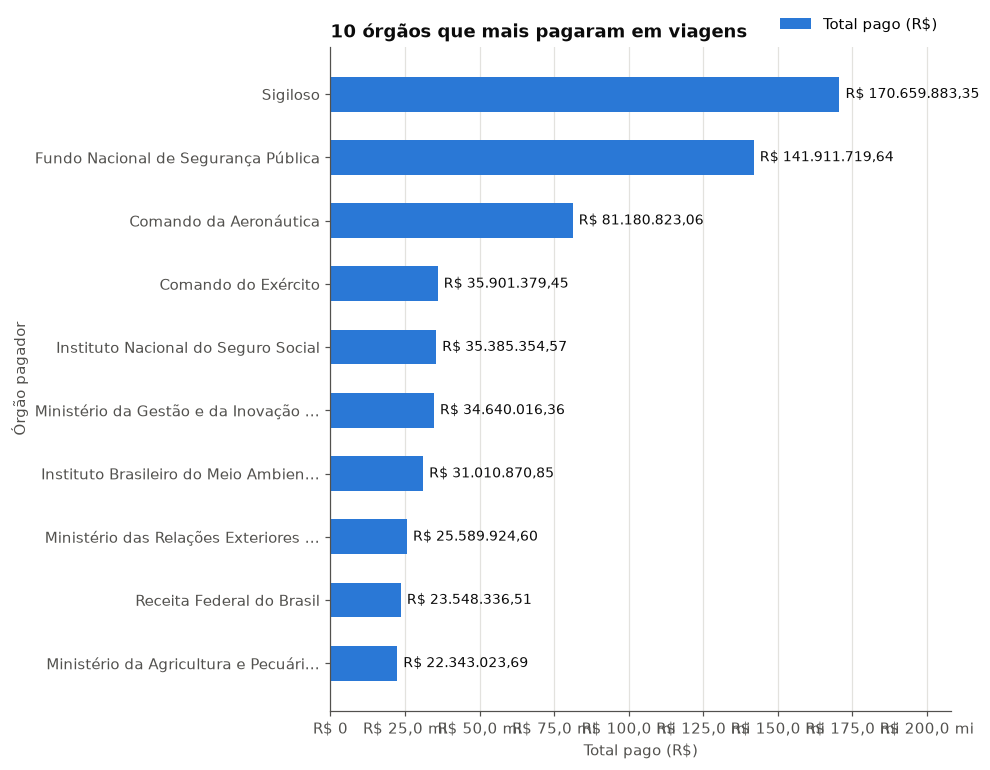

Análise: 'Sigiloso' pagou mais: R$ 170.659.883,35 (16.9% de tudo que foi pago), em 86.878 pagamentos de 51.550 viagens. 'Sigiloso' agrupa pagamentos cujo órgão é protegido por sigilo; entre os órgãos identificados, o maior pagador é 'Fundo Nacional de Segurança Pública', com R$ 141.911.719,64 (14.1% do total).


In [131]:
barras_horizontais(
    p7["orgao_pagador"], p7["total_pago"],
    titulo="10 órgãos que mais pagaram em viagens",
    eixo_x="Total pago (R$)",
    eixo_y="Órgão pagador",
    formatar=moeda,
    formatar_eixo=moeda_eixo,
)

pago_geral = valor_unico(
    "SELECT SUM(total_pago) FROM gold_pagamento_orgao"
)
lider = p7.iloc[0]
insight = (
    f"'{lider['orgao_pagador']}' pagou mais: {moeda(lider['total_pago'])} "
    f"({100 * lider['total_pago'] / pago_geral:.1f}% de tudo que foi pago), "
    f"em {inteiro(lider['qtd_pagamentos'])} pagamentos de "
    f"{inteiro(lider['qtd_viagens'])} viagens."
)
if "sigil" in lider["orgao_pagador"].lower():
    identificados = p7[~p7["orgao_pagador"].str.lower().str.contains("sigil")]
    if not identificados.empty:
        outro = identificados.iloc[0]
        insight += (
            f" 'Sigiloso' agrupa pagamentos cujo órgão é protegido por "
            f"sigilo; entre os órgãos identificados, o maior pagador é "
            f"'{outro['orgao_pagador']}', com {moeda(outro['total_pago'])} "
            f"({100 * outro['total_pago'] / pago_geral:.1f}% do total)."
        )
respostas["Pergunta 7"] = insight
print("Análise:", insight)

## 5. Resumo das respostas

In [132]:
for pergunta in sorted(respostas):
    print(f"{pergunta}: {respostas[pergunta]}\n")

Pergunta 1: 'Ministério da Justiça e Segurança Pública' é o órgão de maior custo: R$ 486.933.121,65 (41.0% de todo o custo). Os 5 maiores somam 71.1% do total, o que mostra o grau de concentração dos gastos.

Pergunta 2: 'Sananduva/RS' tem o maior custo médio: R$ 87.164,61 por viagem, 25.1x a média geral (R$ 3.475,53), em 93 viagens.

Pergunta 3: A viagem 0000000000020699856 (Ministério da Previdência Social) é a mais longa: 384 dias, de 2025-01-13 a 2026-01-31, com custo total de R$ 0,00. A duração média das viagens é de 8.1 dias. Duração acima de 1 ano é incomum e pode indicar proposta de longo prazo ou erro de digitação nas datas. Como essa viagem não tem custo, a mais longa com custo maior que zero é a 0000000000020793594 (Ministério da Justiça e Segurança Pública): 379 dias e R$ 120.650,00.

Pergunta 4: O tipo 'PASSAGEM' tem o maior valor médio: R$ 1.856,78 por pagamento (1.0x a média geral de R$ 1.773,77), em 186.008 pagamentos.

Pergunta 5: 'Veículo Oficial' é o meio mais usado:

In [133]:
conexao.close()

## 6. Conclusões

Os valores acima são calculados a partir dos dados do Portal da Transparência carregados no banco.
Pontos de atenção na leitura:

- **Duplicidades:** pagamentos e passagens 100% idênticos foram contados uma única vez na Silver. O CSV de pagamentos
  não traz um identificador do pagamento, então dois pagamentos legítimos e iguais não podem ser distinguidos de uma repetição.
- **Valores inválidos:** valores negativos ou fora do formato viram `NULL` na Silver e ficam fora das somas e médias.
- **Destino:** o campo `destinos` lista várias cidades, muitas vezes repetidas. Na Pergunta 2 cada cidade é um destino
  e uma viagem com vários destinos entra no cálculo de cada um. "Informações protegidas por sigilo" fica fora do ranking.
- **Informação sigilosa:** parte dos pagamentos tem o órgão pagador "Sigiloso", que lidera a Pergunta 7; a análise mostra
  também o maior pagador identificado.
- **Trechos de volta:** na Pergunta 6, a UF-base dos viajantes aparece em muitos trechos por causa das voltas; a comparação
  com o 1º trecho mostra o destino real das viagens.